# Checking Theorem 2 with noise, on top of `codeword_optimization.ipynb`

`codeword_optimization.ipynb` picks the code using **coherent** dynamics only (hopping inside sector $b$). This notebook asks what happens to that code during a storage round with **noise**, and checks each claim of Theorem 2 numerically next to its analytic prediction.

| § | Claim | Analytic side |
|---|---|---|
| 0 | Your functions, unchanged | copied from `codeword_optimization.ipynb` |
| 1 | The full-space Ising energies are your $E(c)$ | Eq. (1) + a constant |
| 2 | The checks pick out exactly $\{|0_L\rangle,|1_L\rangle\}$ | $\dim=2$ |
| 3 | No noise: leakage in the full space (with $B_x$, pair creation) | your Eq. (2) |
| 4 | $Z$ kicks | Lemma: $16x(K-x)$ silent pairs |
| 5 | **Flip, then flip back on one site** | closed form from $V$, $W$ |

Same conventions as your notebook: sites $i=0,\dots,N-1$, mirror pair $p=(p,\,N-1-p)$, excitation = occupied site, $\sigma^z_i=1-2\hat n_i$. The difference: here we work in the **full** $2^N$ space, because noise ($X$, $Y$ kicks) and the paper's $B_x$ and $J_x\sigma^x\sigma^x$ terms change $b$. That limits us to $N=12$.

## 0. Your functions (copied verbatim from `codeword_optimization.ipynb`, §1–3)

In [1]:
import itertools, time
from collections.abc import Set
from math import comb
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.linalg import eigh


def get_V_W(N, alpha, Jz):
    r = np.abs(np.subtract.outer(np.arange(N), np.arange(N))).astype(float)
    np.fill_diagonal(r, np.inf)
    W = 4.0 * Jz * r ** (-alpha)
    V = -0.5 * W.sum(axis=1)
    return V, W


def config_energy(occ, V, W):
    occ = np.asarray(occ)
    return V[occ].sum() + 0.5 * W[np.ix_(occ, occ)].sum()


def codewords(t):
    A = [p for p, tp in enumerate(t) if tp == 1]
    K = len(A) // 2
    words = [frozenset(S) for S in itertools.combinations(A, K) if A[0] in S]
    return words, A, K


def config_from_S(S, t, N):
    occ = []
    for p, tp in enumerate(t):
        L, R = p, N - 1 - p
        if tp == 2:
            occ += [L, R]
        elif tp == 1:
            occ.append(L if p in S else R)
    return sorted(occ)


def hop_gaps(occ, V, W, N):
    occ_set, occ_arr = set(occ), np.asarray(occ)
    out = []
    for i in occ:
        others = occ_arr[occ_arr != i]
        for j in (i - 1, i + 1):
            if 0 <= j < N and j not in occ_set:
                delta = V[j] - V[i] + (W[j, others] - W[i, others]).sum()
                out.append((i, j, delta))
    return out


def leakage(occ, V, W, N, Jx):
    gaps = np.array([abs(g) for (_, _, g) in hop_gaps(occ, V, W, N)])
    if len(gaps) == 0:
        return 0.0, np.inf
    return 2.0 * np.sum((Jx / gaps) ** 2), gaps.min()

**Parameters and code.** The code is the $N=12$ winner of your §5/§8 search at $\alpha=0.4$, $J_z/J_x=100$: $t=$`111100`, $|0_L\rangle=|v_S\rangle$ with $S=\{0,1\}$, $|1_L\rangle=|v_T\rangle$ with $T=\{0,3\}$. $B_x$ is the stray field of the paper's Eq. (HAM); your notebook leaves it out because it changes $b$.

In [2]:
N, alpha, Jz, Jx, Bx = 12, 0.4, 100.0, 1.0, 0.1
t  = (1, 1, 1, 1, 0, 0)
S  = frozenset({0, 1})
T  = frozenset({0, 3})

words, A, K = codewords(t)
assert S in words and T in words
x = len(S & T)
V, W = get_V_W(N, alpha, Jz)
Sc, Tc = frozenset(A) - S, frozenset(A) - T
for name, X in [('S', S), ('S^c', Sc), ('T', T), ('T^c', Tc)]:
    print(f"|{name}>: occupied {config_from_S(X, t, N)}   E = {config_energy(config_from_S(X, t, N), V, W):.4f}")
print(f"A = {A}, K = {K}, x = |S & T| = {x}")
print("leakage (your Eq. 2):  L(S) =", f"{leakage(config_from_S(S, t, N), V, W, N, Jx)[0]:.3e}",
      "  L(T) =", f"{leakage(config_from_S(T, t, N), V, W, N, Jx)[0]:.3e}")

|S>: occupied [0, 1, 8, 9]   E = -3926.8325
|S^c>: occupied [2, 3, 10, 11]   E = -3926.8325
|T>: occupied [0, 3, 9, 10]   E = -4062.7085
|T^c>: occupied [1, 2, 8, 11]   E = -4062.7085
A = [0, 1, 2, 3], K = 2, x = |S & T| = 1
leakage (your Eq. 2):  L(S) = 1.543e-03   L(T) = 1.992e-02


## 1. The full $2^N$ space

Basis index $k$ ↔ bitstring with site 0 on the left, exactly like your `occupied(k, N)`. Pauli operators are Kronecker products with site 0 as the leftmost factor.

The paper's Hamiltonian, Eq. (HAM):
$$H=\sum_{i<j}\frac{J_z}{|i-j|^\alpha}\sigma^z_i\sigma^z_j+B_x\sum_i\sigma^x_i+J_x\sum_i\sigma^x_i\sigma^x_{i+1}.$$
Its $J_x$ term contains your hopping $T$ **plus** pair creation $\hat a^\dagger_i\hat a^\dagger_{i+1}+{\rm h.c.}$, which changes $b$ by 2.

**Check:** in sector $b$, the diagonal of the Ising term equals your $E(c)$ plus the constant $E_0=\sum_{i<j}J_z|i-j|^{-\alpha}$ (as in your §1b).

In [3]:
dim = 2**N
occ = np.array([[(k >> (N - 1 - i)) & 1 for i in range(N)] for k in range(dim)])   # occ[k, i] = n_i

sx = sp.csr_matrix([[0, 1], [1, 0]], dtype=complex)
sy = sp.csr_matrix([[0, -1j], [1j, 0]])
sz = sp.csr_matrix([[1, 0], [0, -1]], dtype=complex)
def site_op(single, i):                       # sigma on site i (0-indexed), identities elsewhere
    return sp.kron(sp.kron(sp.identity(2**i), single), sp.identity(2**(N - 1 - i)), format='csr')
X = [site_op(sx, i) for i in range(N)]
Y = [site_op(sy, i) for i in range(N)]
Z = [site_op(sz, i) for i in range(N)]

def index_of(sites):                          # occupied sites -> basis index
    return sum(2**(N - 1 - i) for i in sites)
def ket(sites):
    v = np.zeros(dim, complex); v[index_of(sites)] = 1; return v

zdiag = 1 - 2 * occ
Eising = sum(Jz / (j - i)**alpha * zdiag[:, i] * zdiag[:, j] for i in range(N) for j in range(i + 1, N))
H = (sp.diags(Eising) + Bx * sum(X) + Jx * sum(X[i] @ X[i + 1] for i in range(N - 1))).real.tocsr()

E0const = sum(Jz / (j - i)**alpha for i in range(N) for j in range(i + 1, N))
sector4 = [k for k in range(dim) if occ[k].sum() == 4]
diff = max(abs(Eising[k] - E0const - config_energy(np.nonzero(occ[k])[0], V, W)) for k in sector4)
print(f"max |Ising diagonal - E0 - E(c)| over sector b=4: {diff:.1e}")

max |Ising diagonal - E0 - E(c)| over sector b=4: 1.8e-12


## 2. Codewords and checks

The paper measures $\hat N$, $\mathcal R$, every pair total $t_p$, and the products $\hat s_p\hat s_q$ that take equal values on both codewords. A basis state passes the diagonal checks if all return the codeword values; $\mathcal R=+1$ is then imposed with $(1+\mathcal R)/2$.

**Analytic:** the accepted projector has rank 2 and equals $|0_L\rangle\langle0_L|+|1_L\rangle\langle1_L|$.

In [4]:
def vS(X_):
    return (ket(config_from_S(X_, t, N)) + ket(config_from_S(frozenset(A) - X_, t, N))) / np.sqrt(2)
L0, L1 = vS(S), vS(T)
Lmat = np.stack([L0, L1], 1)
active_sites = sorted(i for p in A for i in (p, N - 1 - p))

refl = np.array([index_of([N - 1 - i for i in np.nonzero(occ[k])[0]]) for k in range(dim)])
R = sp.csr_matrix((np.ones(dim), (refl, np.arange(dim))), shape=(dim, dim))

pairs = range(N // 2)
tp = {p: occ[:, p] + occ[:, N - 1 - p] for p in pairs}
sp_ = {p: occ[:, N - 1 - p] - occ[:, p] for p in pairs}          # s_p = n_R - n_L
k0 = index_of(config_from_S(S, t, N))
Delta = S ^ T
prods = [(p, q) for p, q in itertools.combinations(A, 2) if (p in Delta) == (q in Delta)]
print("product checks on pairs:", prods)

ok = occ.sum(1) == occ[k0].sum()
for p in pairs: ok &= tp[p] == tp[p][k0]
for p, q in prods: ok &= sp_[p] * sp_[q] == (sp_[p] * sp_[q])[k0]
print("basis states passing the diagonal checks:", ok.sum())
Pd = sp.diags(ok.astype(float))
Pacc = (Pd @ (sp.identity(dim) + R) / 2 @ Pd).toarray()
print("rank:", int(round(np.trace(Pacc).real)), "  equals |0L><0L|+|1L><1L|:", np.allclose(Pacc, Lmat @ Lmat.conj().T))

product checks on pairs: [(0, 2), (1, 3)]
basis states passing the diagonal checks: 4


rank: 2   equals |0L><0L|+|1L><1L|: True


## Diagonalize $H$ once
Then $e^{-iHt}\psi=Ve^{-iEt}V^\dagger\psi$ for any $t$. About 10–60 s.

In [5]:
t0 = time.time()
Eh, Vh = eigh(H.toarray())
print(f"diagonalized in {time.time()-t0:.1f}s")
def _rmul(M, v):                              # real matrix x complex vector, no complex copy of M
    return M @ v.real + 1j * (M @ v.imag)
def U(tt, psi):
    return _rmul(Vh, np.exp(-1j * Eh * tt) * _rmul(Vh.T, psi))
def U_many(ts, psi):                          # columns = e^{-iHt}psi for each t
    return _rmul(Vh, np.exp(-1j * np.outer(Eh, ts)) * _rmul(Vh.T, psi)[:, None])
def U0(tt, psi):                              # Ising part only (diagonal)
    return np.exp(-1j * Eising * tt) * psi

diagonalized in 11.2s


## 3. No noise: leakage in the full space

Your §6 computed the leakage with hopping only, inside sector $b$. Here $B_x$ and pair creation are on too. In the storage window the two should agree, since sector-changing moves cost $\sim J_zN^{1-\alpha}$.

Leakage of codeword $a$: $\ell_a(t)=1-\|P_{\rm acc}e^{-iHt}|a_L\rangle\|^2$.

|0_L>: full-space average over 0<t<10 = 1.956e-03    your Eq. (2) = 1.543e-03


|1_L>: full-space average over 0<t<10 = 2.093e-02    your Eq. (2) = 1.992e-02


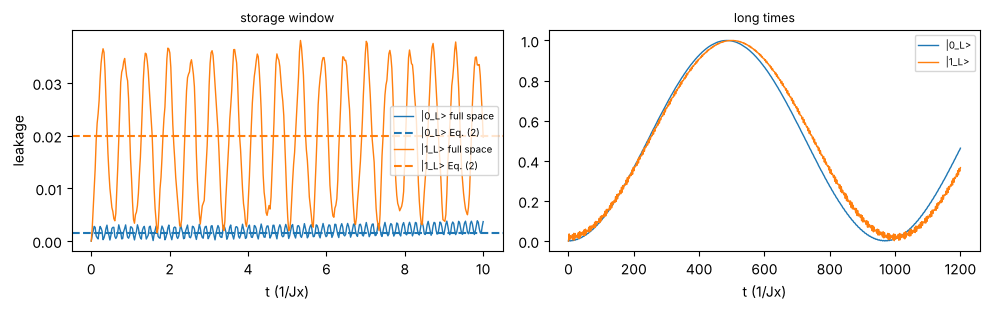

In [6]:
ts = np.linspace(0, 10, 400)
win = np.random.default_rng(0).uniform(0, 10, 400)
tl = np.linspace(0, 1200, 600)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for lab, X_, col in [('|0_L>', S, 'C0'), ('|1_L>', T, 'C1')]:
    v = vS(X_)
    leak = 1 - np.sum(np.abs(Lmat.conj().T @ U_many(ts, v))**2, 0)
    avg = np.mean(1 - np.sum(np.abs(Lmat.conj().T @ U_many(win, v))**2, 0))
    eq2 = leakage(config_from_S(X_, t, N), V, W, N, Jx)[0]
    print(f"{lab}: full-space average over 0<t<10 = {avg:.3e}    your Eq. (2) = {eq2:.3e}")
    ax[0].plot(ts, leak, col, lw=1, label=f'{lab} full space'); ax[0].axhline(eq2, color=col, ls='--', label=f'{lab} Eq. (2)')
    ax[1].plot(tl, 1 - np.sum(np.abs(Lmat.conj().T @ U_many(tl, v))**2, 0), col, lw=1, label=lab)
ax[0].set_xlabel('t (1/Jx)'); ax[0].set_ylabel('leakage'); ax[0].set_title('storage window', fontsize=9); ax[0].legend(fontsize=7)
ax[1].set_xlabel('t (1/Jx)'); ax[1].set_title('long times', fontsize=9); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Left:** Eq. (2) holds in the storage window, with the full Hamiltonian.

**Right: something your sector-$b$ ED cannot see.** At long times the codewords leak completely and come back. Where does the weight go?

In [7]:
psi = U(500.0, L0); w = np.abs(psi)**2
for k in np.argsort(w)[::-1][:4]:
    sites = [int(i) for i in np.nonzero(occ[k])[0]]
    print(f"occupied {sites}   b = {len(sites)}   weight {w[k]:.3f}   E(c) = {config_energy(sites, V, W):.3f}")
bulk = [i for i in range(N) if i not in active_sites]
print("inactive (bulk) sites:", bulk)

occupied [0, 1, 4, 5, 6, 7, 8, 9]   b = 8   weight 0.498   E(c) = -3926.833
occupied [2, 3, 4, 5, 6, 7, 10, 11]   b = 8   weight 0.498   E(c) = -3926.833
occupied [2, 3, 10, 11]   b = 4   weight 0.001   E(c) = -3926.833
occupied [0, 1, 8, 9]   b = 4   weight 0.001   E(c) = -3926.833
inactive (bulk) sites: [4, 5, 6, 7]


The weight goes to the **same codeword with the entire bulk occupied** ($b=4\to8$), at exactly the same Ising energy.

**Why (one line, in spin language).** Flipping a set $F$ of spins changes the Ising energy by $\Delta E=-2\sum_{i\in F}\sum_{j\notin F}J_{ij}\,s_is_j$. Take $F$ = the whole bulk. Every bulk spin is up ($s_i=+1$), and the sites outside $F$ are exactly the active ones. Because $F$ is mirror symmetric, $\sum_{i\in F}J_{ij}$ is the same for $j$ and its mirror $N-1-j$. Each active pair has one spin up and one down, $s_j=-s_{N-1-j}$, so the pair's contributions cancel and $\Delta E=0$ for every codeword.

It takes $(N-2b)/2$ pair creations to get there, so the coupling falls off like $(J_x/J_z)^{(N-2b)/2}$: a timescale of $\sim500/J_x$ at $N=12$, and astronomically long at $N=20$. It does not affect a $\tau=10$ round, but it is a real limit for small chains, and the paper should state it.

In [8]:
for X_ in (S, T):
    c = config_from_S(X_, t, N)
    print(f"E(c) = {config_energy(c, V, W):.6f}    E(c + bulk) = {config_energy(sorted(c + bulk), V, W):.6f}")

E(c) = -3926.832512    E(c + bulk) = -3926.832512
E(c) = -4062.708526    E(c + bulk) = -4062.708526


## 4. Dephasing kicks ($Z$)

**Analytic (paper Lemma 1):** on the code, $Z_{p}=\hat s_p$ and $Z_{N-1-p}=-\hat s_p$ for active pairs, and $Z_i=+1$ on bulk sites. So one $Z$ on an active site makes the state reflection-odd (flagged), and one $Z$ in the bulk does nothing. Two $Z$'s on different active pairs act as $\pm\hat s_p\hat s_q$: a logical $Z$ if exactly one pair is in $S\triangle T$. The paper counts $16x(K-x)$ such site pairs.

In [9]:
plus = (L0 + L1) / np.sqrt(2)
print("one Z kick, accepted probability:")
for i in range(N):
    print(f"  site {i:2d} ({'active' if i in active_sites else 'bulk  '}): {np.linalg.norm(Pacc @ (Z[i] @ plus))**2:.3f}")

counts = {'identity': 0, 'logical Z': 0, 'flagged': 0}
for i, j in itertools.combinations(range(N), 2):
    M = Lmat.conj().T @ (Z[i] @ (Z[j] @ Lmat))
    if np.allclose(M, 0): counts['flagged'] += 1
    elif np.allclose(abs(M), np.eye(2)) and np.isclose(M[0, 0], M[1, 1]): counts['identity'] += 1
    elif np.allclose(abs(M), np.eye(2)): counts['logical Z'] += 1
    else: print("unexpected", i, j, M)
print("\ntwo Z kicks:", counts, "    paper: 16 x (K-x) =", 16 * x * (K - x))

one Z kick, accepted probability:


  site  0 (active): 0.000
  site  1 (active): 0.000
  site  2 (active): 0.000


  site  3 (active): 0.000
  site  4 (bulk  ): 1.000
  site  5 (bulk  ): 1.000


  site  6 (bulk  ): 1.000
  site  7 (bulk  ): 1.000
  site  8 (active): 0.000


  site  9 (active): 0.000
  site 10 (active): 0.000
  site 11 (active): 0.000

two Z kicks: {'identity': 18, 'logical Z': 16, 'flagged': 32}     paper: 16 x (K-x) = 16


## 5. Flip, then flip back on the same site

History: evolve to $t_1$, apply $X_i$, evolve to $t_2$, apply $X_i$ again, evolve to $\tau$. The configuration is restored, but while site $i$ is flipped each branch $c$ picks up the extra phase $\eta_i(c)\,\Delta t$, $\Delta t=t_2-t_1$, with

$$\eta_i(c)=E(c\oplus i)-E(c)=\pm\Big[V(i)+\sum_{k\in c,\,k\neq i}W(i,k)\Big]$$

($+$ if $i$ is empty in $c$, $-$ if occupied). This is your `config_energy`, so it needs no new code.

**Analytic prediction ($H$ = Ising only).** Projecting onto $\mathcal R=+1$, the accepted amplitude of $|v_S\rangle$ is $e^{-i\bar\eta_S\Delta t}\cos(\theta_S/2)$, with $\theta_S=[\eta_i(S)-\eta_i(S^c)]\Delta t$ and $\bar\eta_S=\tfrac12[\eta_i(S)+\eta_i(S^c)]$; the same for $T$. For input $|+_L\rangle$:

$$\text{accept}=\tfrac12(c_S^2+c_T^2),\qquad\text{silent error}=\text{accept}-\tfrac14\big|c_Se^{-i\bar\eta_S\Delta t}+c_Te^{-i\bar\eta_T\Delta t}\big|^2.$$

"Silent error" = accepted, but not the ideal state $e^{-iH\tau}|+_L\rangle$.

**5a. Exact agreement when $H$ = Ising only?**

In [10]:
tau = 10.0
def eta(i, X_):
    c = config_from_S(X_, t, N)
    c2 = sorted(set(c) ^ {i})
    return config_energy(c2, V, W) - config_energy(c, V, W)

def analytic_flipback(i, dt):
    out = []
    for X_ in (S, T):
        e1, e2 = eta(i, X_), eta(i, frozenset(A) - X_)
        out.append((np.cos((e1 - e2) * dt / 2), (e1 + e2) / 2))
    (cS, bS), (cT, bT) = out
    acc = 0.5 * (cS**2 + cT**2)
    return acc, acc - 0.25 * abs(cS * np.exp(-1j * bS * dt) + cT * np.exp(-1j * bT * dt))**2

def numeric_flipback(i, t1, t2, evolve, ideal, op1=None, op2=None):
    op1 = X[i] if op1 is None else op1; op2 = X[i] if op2 is None else op2
    psi = evolve(tau - t2, op2 @ evolve(t2 - t1, op1 @ evolve(t1, plus)))
    acc = np.linalg.norm(Lmat.conj().T @ psi)**2
    return acc, acc - abs(np.vdot(ideal, psi))**2

ideal0 = U0(tau, plus)
rng = np.random.default_rng(1)
print(" site  kind     t1     t2   | accept: numeric  analytic | silent: numeric  analytic")
for i in [0, 1, 4, 5]:
    t1, t2 = np.sort(rng.uniform(0, tau, 2))
    an, nu = analytic_flipback(i, t2 - t1), numeric_flipback(i, t1, t2, U0, ideal0)
    print(f"  {i:2d}  {'active' if i in active_sites else 'bulk  '} {t1:6.3f} {t2:6.3f} |  {nu[0]:.6f}  {an[0]:.6f}     |  {nu[1]:.6f}  {an[1]:.6f}")

 site  kind     t1     t2   | accept: numeric  analytic | silent: numeric  analytic
   0  active  5.118  9.505 |  0.255678  0.255678     |  0.181203  0.181203
   1  active  1.442  9.486 |  0.239990  0.239990     |  0.003023  0.003023
   4  bulk    3.118  4.233 |  0.342994  0.342994     |  0.129663  0.129663
   5  bulk    4.092  8.277 |  0.607781  0.607781     |  0.070381  0.070381


**5b. Average over when the kicks happen.** Kick times are uniform in the round. The phase rates $\eta$ are $\sim J_z$, so after averaging, $\cos^2\to\tfrac12$ and $\cos\to0$, giving a silent error of $\tfrac14$ **on every site, bulk included**.

The paper's proof says bulk sites give 0, because $\bar\eta_S=\bar\eta_T$ there (check that this holds below). But the error doesn't come from $\bar\eta$: it comes from the random relative sign of $c_S$ and $c_T$.

bulk site 4: eta_bar_S - eta_bar_T = 0.00e+00   theta_S rate = -154.79   theta_T rate =   60.90
bulk site 5: eta_bar_S - eta_bar_T = 0.00e+00   theta_S rate =  -39.01   theta_T rate =   12.53
bulk site 6: eta_bar_S - eta_bar_T = 4.55e-13   theta_S rate =   39.01   theta_T rate =  -12.53
bulk site 7: eta_bar_S - eta_bar_T = 4.55e-13   theta_S rate =  154.79   theta_T rate =  -60.90


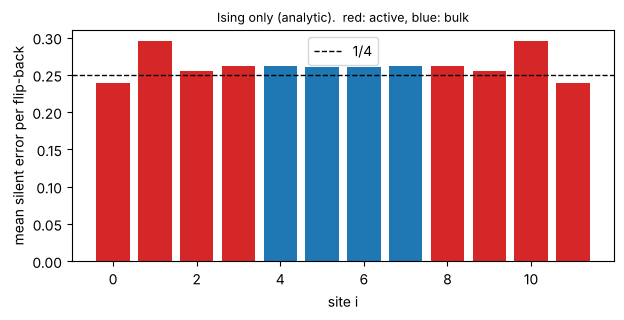

In [11]:
for i in bulk:
    print(f"bulk site {i}: eta_bar_S - eta_bar_T = {(eta(i,S)+eta(i,Sc))/2 - (eta(i,T)+eta(i,Tc))/2:.2e}   "
          f"theta_S rate = {eta(i,S)-eta(i,Sc):7.2f}   theta_T rate = {eta(i,T)-eta(i,Tc):7.2f}")

M_ = 300
t12 = np.sort(np.random.default_rng(2).uniform(0, tau, (M_, 2)), 1)
avg_ising = [np.mean([analytic_flipback(i, b_ - a_)[1] for a_, b_ in t12]) for i in range(N)]
colors = ['C3' if i in active_sites else 'C0' for i in range(N)]
plt.figure(figsize=(7, 3)); plt.bar(range(N), avg_ising, color=colors)
plt.axhline(0.25, color='k', ls='--', lw=1, label='1/4')
plt.xlabel('site i'); plt.ylabel('mean silent error per flip-back')
plt.title('Ising only (analytic).  red: active, blue: bulk', fontsize=9); plt.legend(); plt.show()

**5c. Full Hamiltonian** (hopping, pair creation, $B_x$). The ideal state is now $e^{-iH\tau}|+_L\rangle$.

done in 29s


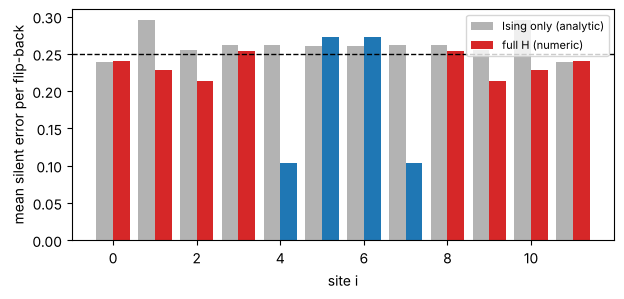

active mean: 0.23395873386734553
bulk mean  : 0.18780571022693515


In [12]:
idealH = U(tau, plus)
nsamp = 60
t0 = time.time()
avg_full = [np.mean([numeric_flipback(i, a_, b_, U, idealH)[1] for a_, b_ in t12[:nsamp]]) for i in range(N)]
print(f"done in {time.time()-t0:.0f}s")
w_ = 0.4
plt.figure(figsize=(7, 3))
plt.bar(np.arange(N) - w_/2, avg_ising, w_, color='0.7', label='Ising only (analytic)')
plt.bar(np.arange(N) + w_/2, avg_full, w_, color=colors, label='full H (numeric)')
plt.axhline(0.25, color='k', ls='--', lw=1); plt.xlabel('site i'); plt.ylabel('mean silent error per flip-back')
plt.legend(fontsize=8); plt.show()
print("active mean:", np.mean([a_ for a_, i in zip(avg_full, range(N)) if i in active_sites]))
print("bulk mean  :", np.mean([a_ for a_, i in zip(avg_full, range(N)) if i not in active_sites]))

**Open question.** With hopping on, bulk sites 4 and 7 drop to ~0.1 while 5 and 6 stay near 0.27. I haven't worked out why. A guess to test with your `hop_gaps`: when site 4 is occupied it sits next to active site 3, which is empty in one branch, so the flipped configuration may have a near-resonant hop. Then the state isn't restored when site 4 flips back, and the round is flagged instead of silently wrong. Either way, bulk sites clearly do **not** give 0.

**5d. Mixed types.** $X$ then $Y$ also restores the configuration, up to a residual $Z_i$: on an active site it replaces $\cos$ by $\sin$, and on a bulk site $Z_i=+1$. The average should again be about $\tfrac14$.

In [13]:
for i in [0, 5]:
    v = np.mean([numeric_flipback(i, a_, b_, U, idealH, op1=X[i], op2=Y[i])[1] for a_, b_ in t12[:nsamp]])
    print(f"site {i} ({'active' if i in active_sites else 'bulk'}), X then Y: mean silent error = {v:.3f}")

site 0 (active), X then Y: mean silent error = 0.219


site 5 (bulk), X then Y: mean silent error = 0.273


## What this tells us about Theorem 2

Two flip-type kicks on one site happen with probability $\tfrac12(\gamma_x+\gamma_y)^2\tau^2$. If each costs about $\tfrac14$ on **every** site, the flip-back part of $\varepsilon$ is

$$\varepsilon_{\rm flip\text{-}back}\approx N\cdot\tfrac14\cdot\tfrac12(\gamma_x+\gamma_y)^2\tau^2=\tfrac N8(\gamma_x+\gamma_y)^2\tau^2,$$

which grows with $N$, instead of the paper's $K(\gamma_x+\gamma_y)^2\tau^2$ (active sites only).

**Check for yourself before moving on**
1. Does 5a agree to all digits? If not, the analytic formula is wrong.
2. In 5b and 5c, are the blue (bulk) bars near $\tfrac14$, or near 0?
3. Swap in another winner from your §5 table (e.g. `t = (1,1,1,0,1,0)`), or change `Jz`, and rerun.

**Next notebook:** weight each piece by its probability to get the total $\varepsilon$ and $p_{\rm flag}$, and compare against a direct Lindblad simulation at small $N$.